In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [3]:
np.random.seed(42)

# Create more overlapping distributions
def generate_overlapping_data(n_samples, Spoiled):
    humidity = np.where(
        Spoiled == 'safe',
        np.random.normal(loc=47, scale=8, size=n_samples),
        np.random.normal(loc=65, scale=12, size=n_samples)
    )
    
    gases = np.where(
        Spoiled == 'safe',
        np.random.normal(loc=80, scale=40, size=n_samples),
        np.random.normal(loc=200, scale=80, size=n_samples)
    )
    
    temperature = np.where(
        Spoiled == 'safe',
        np.random.normal(loc=21, scale=5, size=n_samples),
        np.random.normal(loc=32, scale=7, size=n_samples)
    )
    
    # Add 20% ambiguous cases that could go either way
    ambiguous = np.random.choice([True, False], size=n_samples, p=[0.2, 0.8])
    humidity[ambiguous] = np.random.normal(loc=55, scale=5, size=sum(ambiguous))
    gases[ambiguous] = np.random.normal(loc=150, scale=30, size=sum(ambiguous))
    temperature[ambiguous] = np.random.normal(loc=28, scale=3, size=sum(ambiguous))
    
    return humidity, gases, temperature

# Generate dataset
n_samples = 4000
safe_h, safe_g, safe_t = generate_overlapping_data(n_samples//2, 'safe')
spoil_h, spoil_g, spoil_t = generate_overlapping_data(n_samples//2, 'spoiled')

df = pd.DataFrame({
    'humidity': np.concatenate([safe_h, spoil_h]),
    'gases': np.concatenate([safe_g, spoil_g]),
    'temperature': np.concatenate([safe_t, spoil_t]),
    'Spoiled': ['safe']*(n_samples//2) + ['spoiled']*(n_samples//2)
}).sample(frac=1, random_state=42).reset_index(drop=True)

df['Spoiled'] = df['Spoiled'].map({'safe': 0, 'spoiled': 1})
df.to_csv('wheat_spoilage_final_dataset.csv', index=False)

In [2]:
# Load and prepare data
df = pd.read_csv('wheat_spoilage_final_dataset.csv')

df.head()

,humidity,gases,temperature,Spoiled
0,43.704984,67.981362,21.906270,0
1,69.991072,289.325142,27.266169,1
2,49.116509,131.399312,29.339123,0
3,52.947173,172.575770,28.648768,1
4,60.257781,179.678221,26.791378,1


In [5]:
df.shape

(4000, 4)

In [4]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
humidity,4000.0,56.013738,12.412281,23.476891,47.539092,54.740959,63.190968,102.160346
gases,4000.0,140.276117,79.401199,-92.406921,83.237961,129.291385,183.488606,488.908005
temperature,4000.0,26.869499,7.525848,1.387999,21.715819,26.500231,31.565822,54.507619
Spoiled,4000.0,0.500000,0.500063,0.000000,0.000000,0.500000,1.000000,1.000000


Text(0, 0.5, 'Humidity (%)')

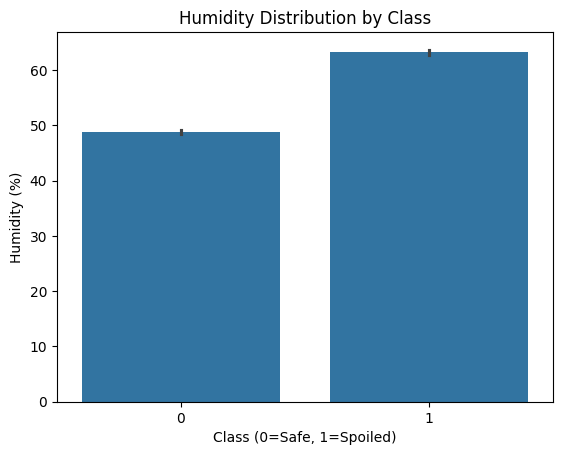

In [6]:
# Humidity distribution
sns.barplot(x='Spoiled', y='humidity', data=df)
plt.title('Humidity Distribution by Class')
plt.xlabel('Class (0=Safe, 1=Spoiled)')
plt.ylabel('Humidity (%)')

Text(0, 0.5, 'Gases (ppm)')

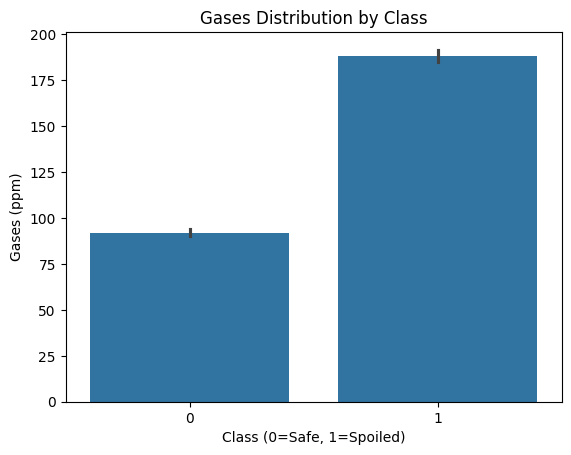

In [7]:
# Gases distribution
sns.barplot(x='Spoiled', y='gases', data=df)
plt.title('Gases Distribution by Class')
plt.xlabel('Class (0=Safe, 1=Spoiled)')
plt.ylabel('Gases (ppm)')

Text(0, 0.5, 'Temperature (°C)')

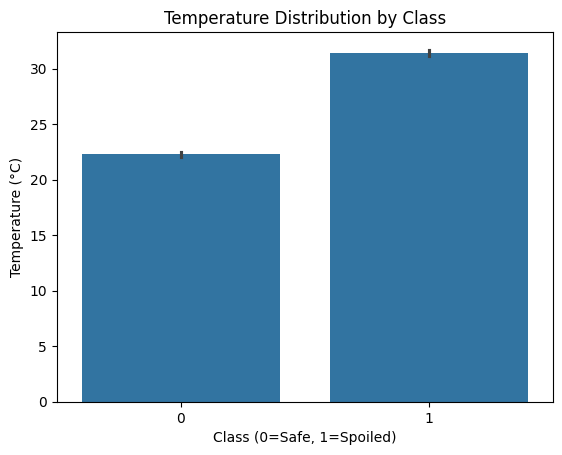

In [8]:
# Temperature distribution
sns.barplot(x='Spoiled', y='temperature', data=df)
plt.title('Temperature Distribution by Class')
plt.xlabel('Class (0=Safe, 1=Spoiled)')
plt.ylabel('Temperature (°C)')

In [9]:
X = df[['humidity', 'gases', 'temperature']]
y = df['Spoiled']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [10]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [11]:
# 1. Logistic Regression
log_reg = LogisticRegression(
    C=0.3,  
    penalty='l2',
    solver='saga',
    max_iter=1000,
    random_state=42
)
log_reg.fit(X_train_scaled, y_train)
log_reg_pred = log_reg.predict(X_test_scaled)
log_reg_acc = accuracy_score(y_test, log_reg_pred)

In [12]:
print(f"Logistic Regression Accuracy: {log_reg_acc:.2f}")
print("\nLogistic Regression Report:")
print(classification_report(y_test, log_reg_pred))

Logistic Regression Accuracy: 0.85

Logistic Regression Report:
              precision    recall  f1-score   support

           0       0.87      0.85      0.86       616
           1       0.84      0.86      0.85       584

    accuracy                           0.85      1200
   macro avg       0.85      0.86      0.85      1200
weighted avg       0.86      0.85      0.86      1200



In [13]:
# 2. Decision Tree
dec_tree = DecisionTreeClassifier(
    max_depth=3, 
    min_samples_split=20,
    min_samples_leaf=15,
    random_state=42
)
dec_tree.fit(X_train_scaled, y_train)
dec_tree_pred = dec_tree.predict(X_test_scaled)
dec_tree_acc = accuracy_score(y_test, dec_tree_pred)

In [14]:
print(f"Decision Tree Accuracy: {dec_tree_acc:.2f}")
print("\nDecision Tree Report:")
print(classification_report(y_test, dec_tree_pred))

Decision Tree Accuracy: 0.84

Decision Tree Report:
              precision    recall  f1-score   support

           0       0.84      0.84      0.84       616
           1       0.83      0.83      0.83       584

    accuracy                           0.84      1200
   macro avg       0.84      0.84      0.84      1200
weighted avg       0.84      0.84      0.84      1200



In [15]:
# 3. Random Forest
rand_forest = RandomForestClassifier(
    n_estimators=50,
    max_depth=4,  # Limited depth
    min_samples_split=15,
    min_samples_leaf=10,
    max_features=2,  # Don't use all features
    random_state=42
)
rand_forest.fit(X_train_scaled, y_train)
rand_forest_pred = rand_forest.predict(X_test_scaled)
rand_forest_acc = accuracy_score(y_test, rand_forest_pred)

In [16]:
print(f"Random Forest Accuracy: {rand_forest_acc:.2f}")
print("\nRandom Forest Report:")
print(classification_report(y_test, rand_forest_pred))

Random Forest Accuracy: 0.86

Random Forest Report:
              precision    recall  f1-score   support

           0       0.86      0.86      0.86       616
           1       0.85      0.85      0.85       584

    accuracy                           0.86      1200
   macro avg       0.86      0.86      0.86      1200
weighted avg       0.86      0.86      0.86      1200



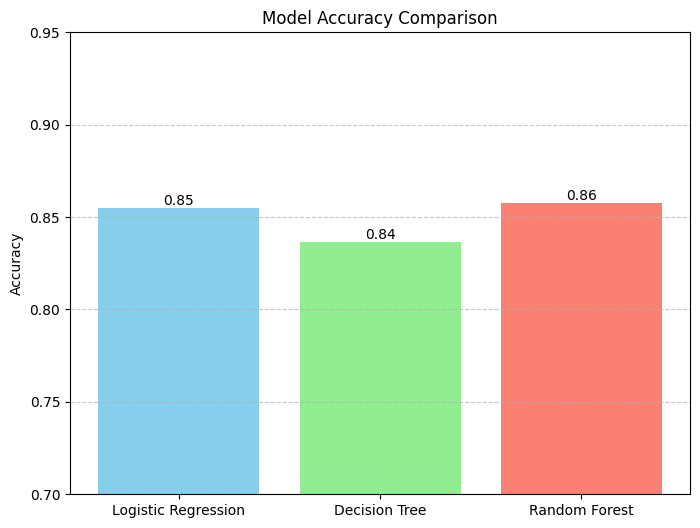

In [17]:
# Accuracy comparison bar chart
models = ['Logistic Regression', 'Decision Tree', 'Random Forest']
accuracies = [log_reg_acc, dec_tree_acc, rand_forest_acc]

plt.figure(figsize=(8, 6))
bars = plt.bar(models, accuracies, color=['skyblue', 'lightgreen', 'salmon'])

plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.ylim(0.7, 0.95)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add values on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.2f}',
             ha='center', va='bottom')

plt.show()

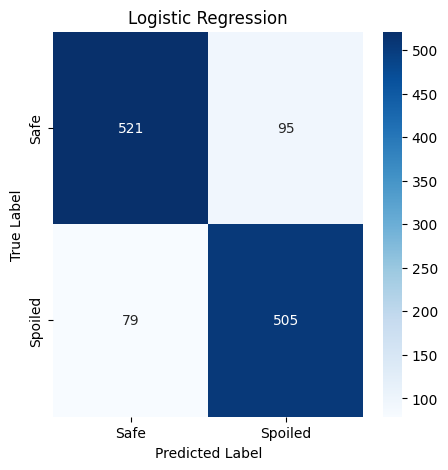

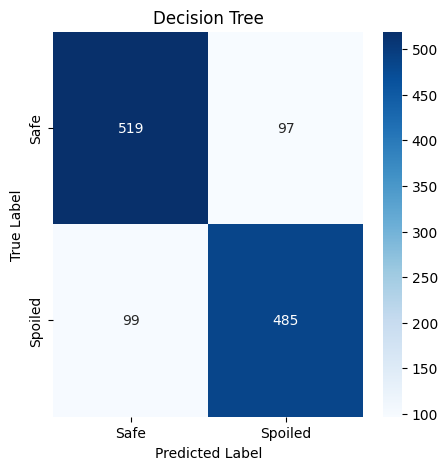

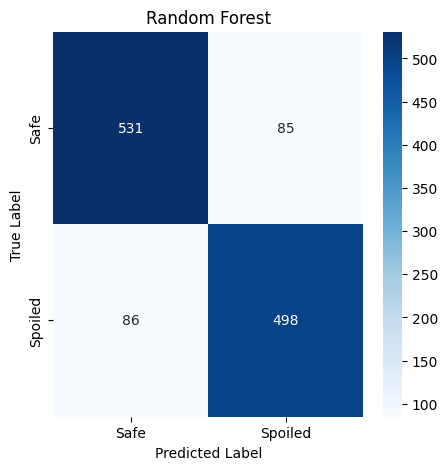

In [18]:
# Confusion Matrix
def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Safe', 'Spoiled'],
                yticklabels=['Safe', 'Spoiled'])
    plt.title(title)
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

# Plot for each model
plot_confusion_matrix(y_test, log_reg_pred, 'Logistic Regression')
plot_confusion_matrix(y_test, dec_tree_pred, 'Decision Tree')
plot_confusion_matrix(y_test, rand_forest_pred, 'Random Forest')

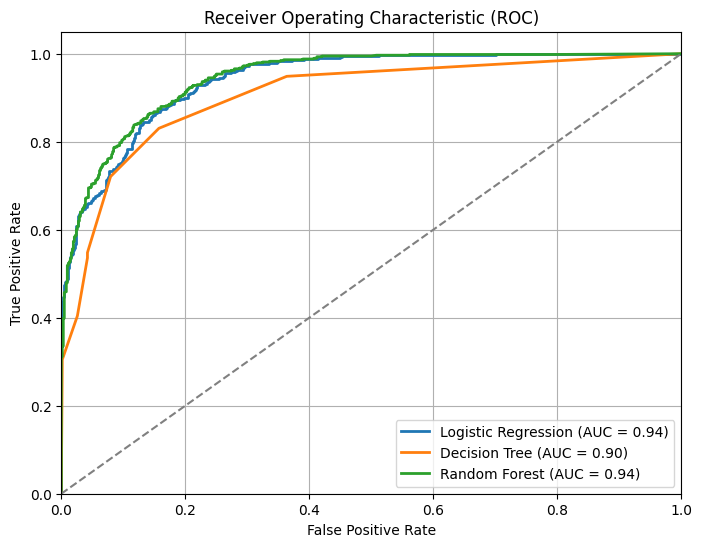

In [19]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))

for model, name in zip([log_reg, dec_tree, rand_forest], 
                      ['Logistic Regression', 'Decision Tree', 'Random Forest']):
    if hasattr(model, "predict_proba"):
        probs = model.predict_proba(X_test_scaled)[:, 1]
    else:  # For models without predict_proba
        probs = model.decision_function(X_test_scaled)
        probs = (probs - probs.min()) / (probs.max() - probs.min())
    
    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [21]:
import joblib

# Save models directly in your "Alina Project" directory
joblib.dump(log_reg, 'logistic_regression_model.pkl')
joblib.dump(dec_tree, 'decision_tree_model.pkl')
joblib.dump(rand_forest, 'random_forest_model.pkl')

# Save the scaler (required for all models)
joblib.dump(scaler, 'scaler.pkl')


print("- logistic_regression_model.pkl")
print("- decision_tree_model.pkl") 
print("- random_forest_model.pkl")
print("- scaler.pkl")

- logistic_regression_model.pkl
- decision_tree_model.pkl
- random_forest_model.pkl
- scaler.pkl
